[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zakariae-lazraq/ai-agents-healthcare-labs/blob/main/notebooks/Lab05_FHIR_Agent.ipynb)

# Lab 5 — An interoperability agent: FHIR results and critical values
**AI Agents for Healthcare and Diagnostics** · Module 4 · about 90 minutes

**The situation.** Northbridge results leave the laboratory as HL7 v2 messages and, increasingly, as FHIR
resources coded with LOINC. An agent that reads them must check the **coding** and the **units** before it
interprets anything, must **never change a value**, must call a human for a **critical value**, and may only
draft a report for review.

**At the end of this lab you will be able to:**
- read the same result as an HL7 v2 OBX segment and as a FHIR Observation;
- build an agent that validates LOINC codes and units, detects duplicates and critical values;
- check its notifications against an answer key and validate the FHIR report it drafts;
- explain how FHIR, HL7 v2 and LOINC protect data integrity when agents are involved.

| Word | Meaning here |
|---|---|
| **HL7 v2** | the classic pipe-delimited laboratory message (segments MSH, PID, OBR, OBX) |
| **FHIR** | the modern standard: JSON "resources" such as Patient, ServiceRequest, Observation, DiagnosticReport |
| **LOINC** | the code that says exactly which test a result is (e.g. 2823-3 = potassium in serum or plasma) |
| **UCUM** | the standard way to write units (mmol/L, mg/dL, 10*9/L) |

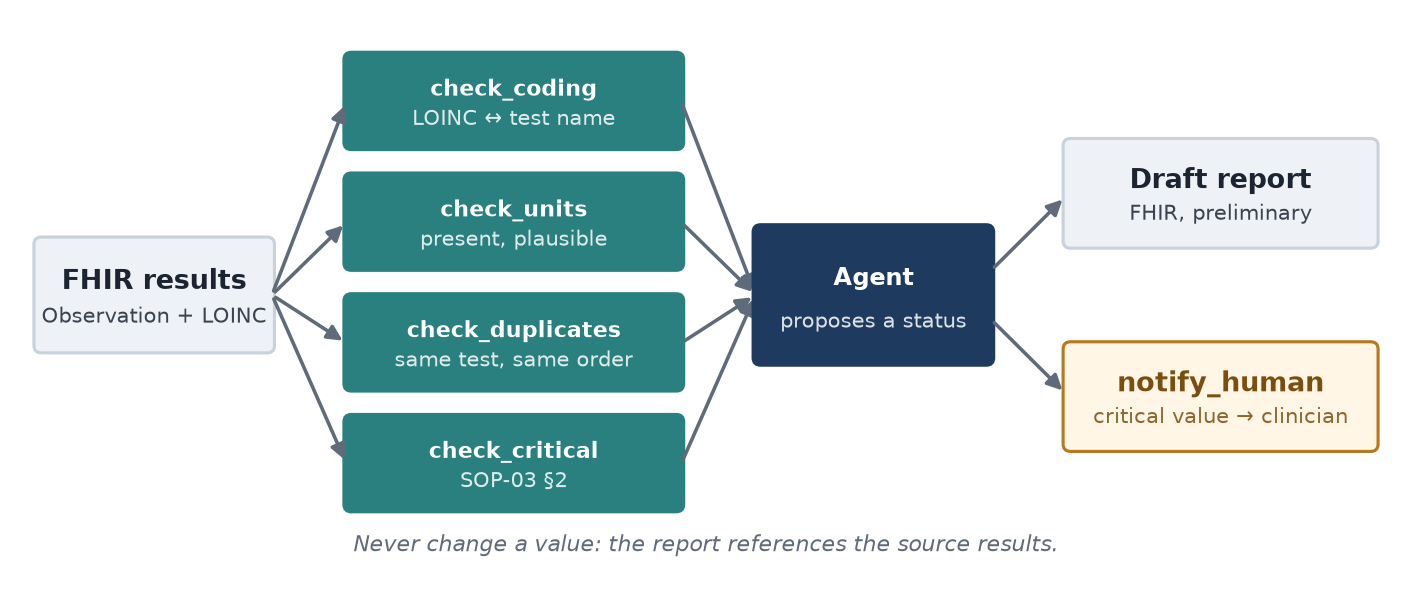

*Four checks before interpretation; a critical value goes to a human; the report is a draft.*

### Setup — run this cell (about 1 minute)
Same as in Lab 0: it installs the course tools, downloads the course files and checks your key. The code is folded: just run it.

In [ ]:
# @title Setup — click run and wait about 1 minute
import os, subprocess, sys
REPO = "https://github.com/zakariae-lazraq/ai-agents-healthcare-labs"
MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        return False
    print(f"done: {what}")
    return True

try:
    import google.colab  # noqa: F401  — present only inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

_ready = True
if IN_COLAB:
    if not os.path.exists("/content/course"):
        _ready = _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    if _ready:
        _ready = _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

SETUP_OK, SETUP_RESULTS = False, []
if _ready:
    from google.adk.agents import Agent
    from labkit.setup import check_environment, show_checks
    from labkit.agents import make_model, run, DETERMINISTIC
    from labkit.ui import check, has_blank, ready, copy_box, done_card
    import json
    import re
    import pandas as pd
    from IPython.display import HTML, display
    from labkit import DATA_DIR
    from labkit import fhirlab
    from labkit.audit import AuditLog
    from labkit.ui import error_line
    import importlib.util
    if importlib.util.find_spec("fhir") is None:
        _step("install fhir.resources (FHIR validator)", [sys.executable, "-m", "pip", "install", "-q", "fhir.resources==8.3.0"])
    LAB = DATA_DIR / "lab05"
    LAB5 = fhirlab.load(LAB)
    KEY = json.loads((LAB / "answer_key.json").read_text(encoding="utf-8"))
    _t = fhirlab.make_fhir_tools(LAB5)
    (get_observations, lookup_loinc, check_coding, check_units, check_critical, check_duplicates,
     draft_diagnostic_report, notify_human) = (_t[k] for k in ("get_observations", "lookup_loinc", "check_coding",
        "check_units", "check_critical", "check_duplicates", "draft_diagnostic_report", "notify_human"))
    LOG = AuditLog()
    SETUP_RESULTS = check_environment(MODEL, ping_pubmed=False)
    SETUP_OK = show_checks(SETUP_RESULTS)

**What you should see:** every line marked **OK**, then *"Everything is ready"*. Same Setup as Lab 0.

**If it does not work**

| You see | Do this |
|---|---|
| FIX — API key found | Open Secrets (key icon, left sidebar): `GOOGLE_API_KEY`, *Notebook access* on; run Setup again |
| FIX — API key works, "busy" or "quota" | Wait 30–60 seconds, run Setup again |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 1 — One result, two formats (about 25 minutes)
Below: the HL7 v2 message the LIS sent for patient pat-09, field by field, then the same potassium result as a
FHIR Observation. Then the laboratory's LOINC table (15 tests) and the critical value list (SOP-03 §2, Lab 1).

In [ ]:
# @title The HL7 v2 message, field by field — run this cell
_hl7 = (LAB / "oru_example.hl7").read_text(encoding="utf-8")
print(_hl7.replace("\r", "\n"))
display(HTML(fhirlab.hl7_guide_html(_hl7)))

In [ ]:
# @title The same result as a FHIR Observation (and the Patient it points to) — run this cell
_k = next(o for o in LAB5.observations("pat-09") if o["code"]["coding"][0]["code"] == "2823-3")
print(json.dumps(_k, indent=2))
print("Observation.subject points to this Patient resource:")
print(json.dumps(LAB5.by_id[("Patient", "pat-09")], indent=2))

In [ ]:
# @title The LOINC table and the critical values — run this cell
display(pd.read_csv(LAB / "loinc_table.csv"))
display(pd.read_csv(LAB / "critical_values.csv"))

### Task 1 — Match HL7 v2 fields to FHIR elements
<sub>IN THE NOTEBOOK · ABOUT 7 MIN</sub>

**Your task.** Find the same information in both formats — the basis of every interface an agent will read.

**Steps**

1. For each HL7 v2 field, choose the FHIR element that carries the same information.
2. Look carefully at OBX-8 (`HH`): where is it in the FHIR Observation? Is it there at all?
3. Run the cell and the CHECK.

In [ ]:
# @title Match each HL7 v2 field to its FHIR element
# YOUR CELL — fill in the form on the right, then run this cell
OBX_3 = "choose…"  # @param ["choose…", "Observation.code", "Observation.valueQuantity.value", "Observation.valueQuantity.unit", "Patient.identifier", "Observation.subject → Patient.identifier", "not present in this Observation"]
OBX_5 = "choose…"  # @param ["choose…", "Observation.code", "Observation.valueQuantity.value", "Observation.valueQuantity.unit", "Patient.identifier", "Observation.subject → Patient.identifier", "not present in this Observation"]
OBX_6 = "choose…"  # @param ["choose…", "Observation.code", "Observation.valueQuantity.value", "Observation.valueQuantity.unit", "Patient.identifier", "Observation.subject → Patient.identifier", "not present in this Observation"]
PID_3 = "choose…"  # @param ["choose…", "Observation.code", "Observation.valueQuantity.value", "Observation.valueQuantity.unit", "Patient.identifier", "Observation.subject → Patient.identifier", "not present in this Observation"]
OBX_8 = "choose…"  # @param ["choose…", "Observation.code", "Observation.valueQuantity.value", "Observation.valueQuantity.unit", "Patient.identifier", "Observation.subject → Patient.identifier", "not present in this Observation"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_want = {"OBX_3": "Observation.code", "OBX_5": "Observation.valueQuantity.value",
         "OBX_6": "Observation.valueQuantity.unit", "PID_3": "Observation.subject → Patient.identifier",
         "OBX_8": "not present in this Observation"}
_alt = {"PID_3": {"Patient.identifier"}}   # also right: the MRN lives on the Patient resource
_ok = check([(globals()[k] == v or globals()[k] in _alt.get(k, ()), f"{k.replace('_', '-')} → {v}",
              "Look at the field guide and the JSON again.") for k, v in _want.items()])
if _ok:
    MAPPING_DONE = True
    print("OBX-8 'HH' (critically high) has no counterpart here: FHIR would use Observation.interpretation, "
          "and this sender left it out. The agent must therefore check critical values itself (SOP-03).")
    print("PID-3: the Observation only points to Patient/pat-09 (subject); the MRN itself is in the Patient "
          "resource — follow the reference. OBX-7 (reference range 3.5-5.1) is also missing: FHIR would use "
          "Observation.referenceRange.")

<details><summary><b>Hint</b> — open only if you are stuck</summary>

OBX-3 is the test code, OBX-5 the value, OBX-6 the unit, PID-3 the MRN. Search the JSON for 'interpretation': it is not there — a real gap between two messages carrying 'the same' result.

</details>

### Task 2 — Ask Gemini to compare the two formats
<sub>IN THE GEMINI APP · ABOUT 6 MIN</sub>

**Your task.** Use Gemini as a tutor on a standard you do not know by heart — and check what it says.

**Steps**

1. Copy the HL7 message and the FHIR JSON above into the Gemini app and ask: *Do these two messages carry the same information? List what is in one and not in the other, and whether this result needs urgent action.*
2. Record in the form whether Gemini noticed the missing critical flag (OBX-8 HH vs no interpretation).
3. Run the cell and the CHECK.

In [ ]:
# @title What did Gemini notice?
# YOUR CELL — fill in the form on the right, then run this cell
gemini_noticed = "choose…"  # @param ["choose…", "Noticed the missing critical flag and the urgency", "Compared the fields but missed the flag", "Got a field wrong", "Gemini app not available to me"]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_ok = check([(gemini_noticed != "choose…", "Result recorded", "Choose an option in the form.")])
if _ok:
    GEMINI_COMPARE = gemini_noticed

<details><summary><b>Hint</b> — open only if you are stuck</summary>

A good answer names OBX-8 'HH' and says the FHIR version lacks Observation.interpretation — and that 6.8 mmol/L potassium is above the critical limit whatever the flag says.

</details>

## Part 2 — The agent (about 50 minutes)
The checks are ready, one call per patient. Try one by hand: what does `check_units` report for pat-05?

In [ ]:
check_units("pat-05")   # also try check_coding("pat-03"), check_critical("pat-09"), check_duplicates("pat-18")

### Task 3 — Write the agent's instruction
<sub>IN THE NOTEBOOK · ABOUT 8 MIN</sub>

**Your task.** Turn the laboratory's interface rules into rules the agent must follow.

**Steps**

1. **Validate first:** call check_coding, check_units, check_duplicates and check_critical before interpreting (they can be called together).
2. **Integrity:** never change, round or recompute a value.
3. **Status rules:** critical value = ESCALATE + `notify_human` (urgent); coding, unit or duplicate problem = HOLD (name the check); nothing = PASS.
4. **Draft only:** always call draft_diagnostic_report (preliminary, for human review).
5. **Fixed ending:** `STATUS: PASS / HOLD / ESCALATE`. Run your cell and the CHECK.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
FHIR_INSTRUCTION = """___"""

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_i = FHIR_INSTRUCTION.lower()
_blank = has_blank(FHIR_INSTRUCTION)
_ok = check([(False, "Instruction written", _blank)]) if _blank else check([
    (all(c in _i for c in ("check_coding", "check_units", "check_duplicates", "check_critical")),
     "All four checks named", "Name check_coding, check_units, check_duplicates and check_critical."),
    (bool(re.search(r"(never|do not|don't|must not)\s+(change|modify|alter|edit|round|recompute)", _i)),
     "Values are never changed", "Write: never change a value."),
    ("notify_human" in _i and "escalate" in _i, "Critical value → ESCALATE + notify_human",
     "Write: a critical value = ESCALATE and call notify_human."),
    ("draft_diagnostic_report" in _i, "Drafts the report", "Ask it to call draft_diagnostic_report."),
    ("status:" in _i and all(s in _i for s in ("pass", "hold")), "Fixed ending",
     "End with STATUS: PASS / HOLD / ESCALATE."),
])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Same pattern as Lab 2: tools check, the agent applies status rules, a human decides. The new rule is integrity: the agent reports values, it never edits them.

</details>

In [ ]:
# @title Build the agent and review pat-09 — run this cell
TOOLS = [get_observations, lookup_loinc, check_coding, check_units, check_critical, check_duplicates,
         draft_diagnostic_report, notify_human]
if ready("fhir_reviewer", FHIR_INSTRUCTION, TOOLS, example="check_units"):
    LAB5.notifications.clear(); LAB5.drafts.clear()
    fhir_agent = Agent(name="fhir_reviewer", model=make_model(MODEL), instruction=FHIR_INSTRUCTION, tools=TOOLS,
                       generate_content_config=DETERMINISTIC, after_tool_callback=LOG.callback)
    _r = run(fhir_agent, "Review the laboratory results of patient pat-09.")
    print("Parsed status:", fhirlab.parse_status(_r.text), "· notifications so far:", LAB5.notifications)
else:
    fhir_agent = None

### The patients, scored against the answer key
By default the 8 patients with a planted problem plus 2 clean ones (about 2 minutes, quota-friendly); tick
`run_all_20` for all 20. A re-run only repeats patients that did not run. The scoreboard also checks the notifications: **exactly** the
critical patient must be notified — no missed critical value, no false alarm.

In [ ]:
# @title Review the 20 patients and score them — run this cell
if globals().get("fhir_agent") is None:
    display(error_line("Build the agent first (Task 3 and the cell after it)."))
else:
    LAB5.notifications.clear(); LAB5.drafts.clear()
    run_all_20 = False  # @param {type:"boolean"}
    _ids = LAB5.patients if run_all_20 else [p for p in LAB5.patients if KEY[p]["status"] != "PASS"] +                [p for p in LAB5.patients if KEY[p]["status"] == "PASS"][:2]
    FHIR_RESULTS = fhirlab.run_patients(fhir_agent, _ids, previous=globals().get("FHIR_RESULTS"))
    _html, FHIR_SCORE, NOTIFY_OK = fhirlab.scoreboard_html(FHIR_RESULTS, KEY, LAB5.notifications)
    display(HTML(_html))
    from labkit import saved as _saved
    if _saved.not_run(FHIR_RESULTS, "patient_id"):
        display(HTML(_saved.html("lab05", _saved.not_run(FHIR_RESULTS, "patient_id"))))
    display(pd.DataFrame(LAB5.notifications) if LAB5.notifications else "No notification sent.")
    display(HTML(LOG.html()))
    print(f"Post in the course chat → FHIR agent: {FHIR_SCORE}/{len([r for r in FHIR_RESULTS if r['status']])} · notifications {'OK' if NOTIFY_OK else 'NOT OK'}")

### Task 4 — Validate a drafted report — and try to break it
<sub>IN THE NOTEBOOK · ABOUT 8 MIN</sub>

**Your task.** A drafted DiagnosticReport must be valid FHIR, preliminary, and reference results that exist.

**Steps**

1. Choose a patient whose report was drafted and a way to break a copy of it (or none).
2. Run your cell: it validates the report with `fhir.resources` and the laboratory's rules.
3. Run the CHECK. Try at least one break: what does the validator say?

In [ ]:
# @title Validate a drafted report
# YOUR CELL — fill in the form on the right, then run this cell
patient = "pat-09"  # @param ["pat-01", "pat-03", "pat-05", "pat-09", "pat-16", "pat-18"]
break_it = "none"  # @param ["none", "mark it final", "point to a result that does not exist", "remove the code"]
_rep = json.loads(json.dumps(LAB5.drafts.get(patient, {})))
if not _rep:
    display(error_line(f"No draft for {patient} yet: run the 20-patient cell above first."))
else:
    if break_it == "mark it final":
        _rep["status"] = "final"
    elif break_it == "point to a result that does not exist":
        _rep["result"] = _rep["result"] + [{"reference": "Observation/obs-99-1"}]
    elif break_it == "remove the code":
        _rep.pop("code", None)
    print(json.dumps(_rep, indent=2)[:1500])
    VALIDATION = fhirlab.validate_report(LAB5, _rep)
    print("\nValidation:", "VALID" if not VALIDATION else "")
    for _p in VALIDATION:
        print(" -", _p)

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_ok = check([("VALIDATION" in globals(), "A report was validated", "Run your cell after the 20-patient run."),
             ("VALIDATION" in globals() and (break_it == "none") == (VALIDATION == []),
              "The validator caught your break (or accepted the untouched report)",
              "Run your cell again: an untouched draft must be VALID, a broken one must not.")])
if _ok:
    REPORT_VALIDATED = True

<details><summary><b>Hint</b> — open only if you are stuck</summary>

`fhir.resources` checks the structure (required fields, types). The laboratory adds its own rules: a draft is never 'final', and every result it cites must exist. Both layers are needed.

</details>

In [ ]:
# @title Integrity check: did the agent change any value? — run this cell
_bad = fhirlab.integrity_problems(LAB5)
print(f"{len(LAB5.drafts)} reports drafted ({', '.join(LAB5.drafts) or 'none'}) · integrity problems: {len(_bad)}")
for _b in _bad:
    print("  -", _b)
print("Checked: every cited result exists, and every number in each conclusion is a source value of that patient.")

## Discussion (8 minutes, with the group)
1. The HL7 message flagged HH; the FHIR resource did not. Who is responsible for the critical value call?
2. Why must coding and units be validated *before* interpretation? Give an example from your own laboratory.
3. How do FHIR, HL7 v2 and LOINC protect data integrity when an agent is in the loop — and where do they not?
4. The draft report is valid FHIR. Is it therefore correct? What else must a human check?

### Task 5 — Add a delta check
<sub>OPTIONAL CHALLENGE · ABOUT 12 MIN</sub>

**Your task.** For fast finishers. Compare each result with the patient's previous one and flag large changes.

**Steps**

1. Complete the blank: the change limit is **50** %.
2. Run your cell, then the CHECK: it adds your tool to a new agent and reviews pat-12 (creatinine 0.9 → 2.4 mg/dL), which passes all four standard checks.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
def check_delta(patient_id: str) -> dict:
    """Compare each result with the patient's previous result for the same test; flag changes above 50 %."""
    flagged = []
    for o in LAB5.observations(patient_id):
        code = o["code"]["coding"][0]["code"]
        value = o.get("valueQuantity", {}).get("value")
        prev = LAB5.previous.get(patient_id, {}).get(code)
        if prev and value is not None and prev["value"]:      # no division by zero
            change = (value - prev["value"]) / prev["value"] * 100
            if abs(change) > ___:
                flagged.append({"observation_id": o["id"], "loinc_code": code, "previous": prev,
                                "value": value, "change_pct": round(change)})
    return {"patient_id": patient_id, "delta_flags": flagged}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
try:
    _d12, _d01 = check_delta("pat-12")["delta_flags"], check_delta("pat-01")["delta_flags"]
    _err = ""
except Exception as _e:
    _d12, _d01, _err = [], ["?"], f"Your tool raised an error: {_e}"
_ok = check([(bool(_d12), "pat-12 creatinine jump flagged", _err or "Use abs(change) > 50."),
             (not _d01, "pat-01 stable potassium not flagged", _err or "The limit is 50 %.")])
if _ok and globals().get("fhir_agent") is not None:
    fhir_agent_delta = Agent(name="fhir_reviewer", model=make_model(MODEL), tools=TOOLS + [check_delta],
                             instruction=FHIR_INSTRUCTION + "\nAlso call check_delta; a delta flag = HOLD.",
                             generate_content_config=DETERMINISTIC, after_tool_callback=LOG.callback)
    _r = run(fhir_agent_delta, "Review the laboratory results of patient pat-12.")
    print("Parsed status:", fhirlab.parse_status(_r.text))
    DELTA_DONE = True

<details><summary><b>Hint</b> — open only if you are stuck</summary>

`abs(change) > 50`. A delta check catches what single-result checks cannot: a plausible value that is implausible *for this patient* (sample mix-up, or a real and important change). Real laboratories use analyte-specific delta limits (absolute or %, per time window) — one 50 % rule is a teaching shortcut.

</details>

## What you learned
1. **Standards carry meaning:** LOINC says which test, UCUM which unit — check both before interpreting.
2. **The same result, two formats, not always the same information** (the missing HH flag).
3. **Critical values go to a human**, every time, and only those — measured on the scored patients.
4. **Agents draft, humans sign:** a valid FHIR draft is not a correct report; values are never edited.

## Finish — your status card
Type your name, run the cell, post a screenshot in the course chat.

In [ ]:
# @title Status card — type your name, run, then screenshot the card
participant_name = ""  # @param {type:"string"}
import datetime
_g = globals()
_lines = [f"Participant: {participant_name.strip() or 'NAME MISSING — type it in the box'}",
          f"Date: {datetime.date.today().isoformat()} · model {_g.get('MODEL', '?')}",
          f"{'OK ' if 'MAPPING_DONE' in _g else 'FIX'} — HL7 v2 ↔ FHIR mapping (Task 1)",
          f"{'OK ' if 'GEMINI_COMPARE' in _g else 'n/a'} — Gemini format comparison (Task 2, optional)",
          f"{'OK ' if 'FHIR_SCORE' in _g else 'FIX'} — FHIR agent: {_g.get('FHIR_SCORE', '?')}/"
          f"{len([r for r in _g.get('FHIR_RESULTS', []) if r['status']]) or '?'} patients right, "
          f"notifications {'OK' if _g.get('NOTIFY_OK') else 'not OK'}",
          f"{'OK ' if 'REPORT_VALIDATED' in _g else 'FIX'} — Draft report validated (Task 4)",
          f"{'OK ' if 'DELTA_DONE' in _g else 'n/a'} — Delta check (challenge)"]
done_card("Lab 5 — status", _lines, complete=bool(participant_name.strip()) and all(
    k in _g for k in ("MAPPING_DONE", "FHIR_SCORE", "REPORT_VALIDATED")))

**Next: Lab 6 — Hallucination hunt and the guardian agent.** A second agent checks every answer before anyone
sees it.

*Course material for training only. All patients are fictional; MRNs follow the course format NB-xxxxxx.*